# Peri-event analysis

Build a raster and peri-event time histogram (PSTH) from the same observed
events. We simulate two cue-responsive units and an acquisition gap, retain
only complete event windows, and keep event and unit identities in the results.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).

This notebook creates its own data. Times are seconds, rates are Hz, and every
recording or analysis interval is half-open: `[start, stop)`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial.events import (
    population_peri_event_histogram,
    time_to_nearest_event,
)
from neurospatial.simulation import generate_poisson_spikes

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(10, 6))

## 1. Create events, responses, and acquisition coverage

Cue times have independent jitter. Unit 7 has an early response; unit 42 has
a later response. These imposed responses illustrate alignment, rather than
establishing a causal effect or testing for significant modulation.

Electrophysiology is unavailable from 80 to 100 s even though the session
clock continues. Removing spikes in that interval does not make it recorded
silence: we must pass the acquisition windows to the PSTH calculation.

In [2]:
event_rng = np.random.default_rng(42)
duration = 180.0
times = np.arange(0.0, duration + 0.001, 0.002)
regular_events = np.arange(10.0, 180.0, 15.0)
regular_events += event_rng.uniform(-0.3, 0.3, regular_events.size)
event_times = np.sort(np.r_[regular_events, [0.2, 79.8, 90.0, 100.2, 179.8]])
event_names = np.array([f"cue_{index:02d}" for index in range(len(event_times))])
spike_window = np.array([[0.0, 80.0], [100.0, duration]])
epochs = np.array([[5.0, 175.0]])  # separate analysis choice
unit_ids = np.array([7, 42])

spike_trains = []
for latency, amplitude, seed in [(0.15, 24.0, 142), (0.40, 14.0, 143)]:
    rate = np.full(times.size, 2.0)
    for event in event_times:
        rate += amplitude * np.exp(-0.5 * ((times - event - latency) / 0.08) ** 2)
    # Distinct seeds for event jitter and each unit's spike generation.
    spikes = generate_poisson_spikes(rate, times, seed=seed, refractory_period=0.0)
    recorded = np.zeros(spikes.size, dtype=bool)
    for start, stop in spike_window:
        recorded |= (spikes >= start) & (spikes < stop)
    spike_trains.append(spikes[recorded])

print(f"Input events: {len(event_times)}; unit labels: {unit_ids.tolist()}")
print(f"Recorded spikes per unit: {[len(train) for train in spike_trains]}")

Input events: 17; unit labels: [7, 42]
Recorded spikes per unit: [368, 378]


## 2. Select complete event windows once

An event is retained only when its entire `[-0.5, 1.0)` s window lies within
both the analysis epochs and the spike recording support. A window crossing
either side of the gap is excluded, even when the event itself was observed.

`event_indices` refers to positions in the original event array, in input
order. Use it to select event metadata and raster rows; reconstructing a
separate selection can accidentally give the raster a different cohort.

In [3]:
window = (-0.5, 1.0)
bin_size = 0.025
population = population_peri_event_histogram(
    spike_trains,
    event_times,
    window=window,
    bin_size=bin_size,
    unit_ids=unit_ids,
    epochs=epochs,
    spike_window=spike_window,
)
result = population.sel(unit_id=7)
retained_events = event_times[result.event_indices]
retained_names = event_names[result.event_indices]
assert retained_events.size == result.n_events
np.testing.assert_array_equal(result.event_indices, population.event_indices)
assert result.n_events + result.n_events_dropped == event_times.size
print(
    f"Retained {result.n_events}; excluded {result.n_events_dropped} incomplete windows"
)
print(f"Retained event identities: {retained_names.tolist()}")

Retained 9; excluded 8 incomplete windows
Retained event identities: ['cue_01', 'cue_02', 'cue_03', 'cue_04', 'cue_05', 'cue_11', 'cue_12', 'cue_13', 'cue_14']


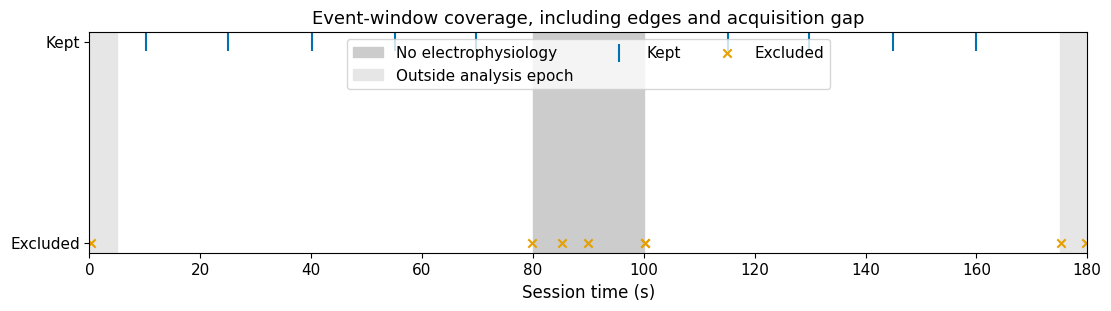

In [4]:
retained = np.zeros(event_times.size, dtype=bool)
retained[result.event_indices] = True
fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
ax.axvspan(80, 100, color="0.8", label="No electrophysiology")
ax.axvspan(0, 5, color="0.9", label="Outside analysis epoch")
ax.axvspan(175, duration, color="0.9")
ax.scatter(
    event_times[retained], np.ones(retained.sum()), marker="|", s=180, label="Kept"
)
ax.scatter(
    event_times[~retained], np.zeros((~retained).sum()), marker="x", label="Excluded"
)
ax.set(xlim=(0, duration), yticks=[0, 1], yticklabels=["Excluded", "Kept"])
ax.set_xlabel("Session time (s)")
ax.set_title("Event-window coverage, including edges and acquisition gap")
ax.legend(loc="upper center", ncol=3)
plt.show()

## 3. Plot one unit's matching raster and PSTH

Each row below represents one retained cue, ordered as in the input event
array. The histogram is the mean spike count per bin across those same cues.
`plot_peri_event_response` uses the result's retained event indices and actual
half-open histogram bin range for both views. Pass the original event array,
including excluded cues, and the spike train belonging to the selected unit.
The helper displays the mean and SEM in Hz. With a window that is not divisible
by `bin_size`, both panels omit the trailing partial bin.

The shaded SEM describes variability across retained events under an
independence assumption. It is not a confidence band for a cell-type claim.
Overlapping events or correlated trials require an appropriate resampling
design. With a single retained event, the SEM is undefined (NaN).

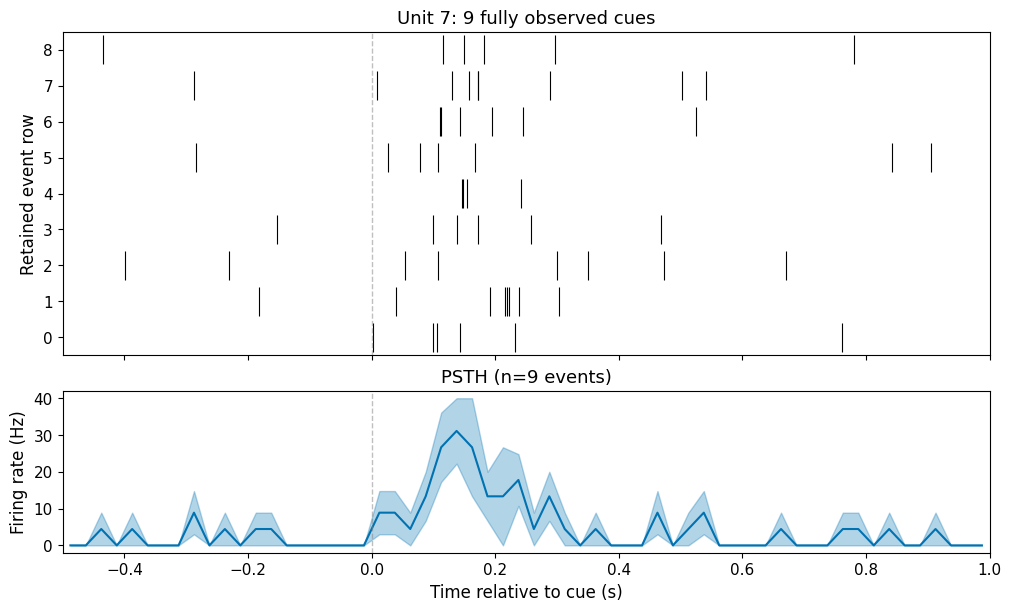

In [5]:
from neurospatial.events import plot_peri_event_response

raster_ax, rate_ax = plot_peri_event_response(spike_trains[0], event_times, result)
fig = raster_ax.figure
raster_ax.set_title(f"Unit {result.unit_id}: {result.n_events} fully observed cues")
rate_ax.set_xlabel("Time relative to cue (s)")
plt.show()

## 4. Compare labeled units on the same cohort

Population rows retain the supplied unit labels. These are absolute firing
rates, so differences in response size and baseline remain visible. Averages
across units answer a different question from variability across events.

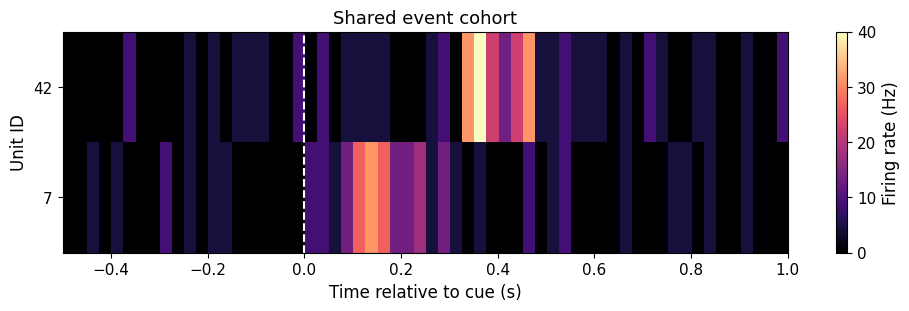

In [6]:
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
image = ax.imshow(
    population.firing_rates,
    aspect="auto",
    origin="lower",
    extent=[window[0], window[1], -0.5, population.n_units - 0.5],
    cmap="magma",
)
ax.set_yticks(np.arange(population.n_units), labels=population.unit_ids)
ax.axvline(0, color="white", linestyle="--")
ax.set(xlabel="Time relative to cue (s)", ylabel="Unit ID", title="Shared event cohort")
fig.colorbar(image, ax=ax, label="Firing rate (Hz)")
plt.show()

## 5. Turn event times into a continuous covariate

Signed nearest-event time is negative before a cue and positive after it.
It includes future events and jumps at midpoints between cues, so it is an
offline descriptive feature. For a causal predictor, use time since the last
event. Choosing this feature does not fit a response model or establish that
event timing explains activity beyond position or other behavior.

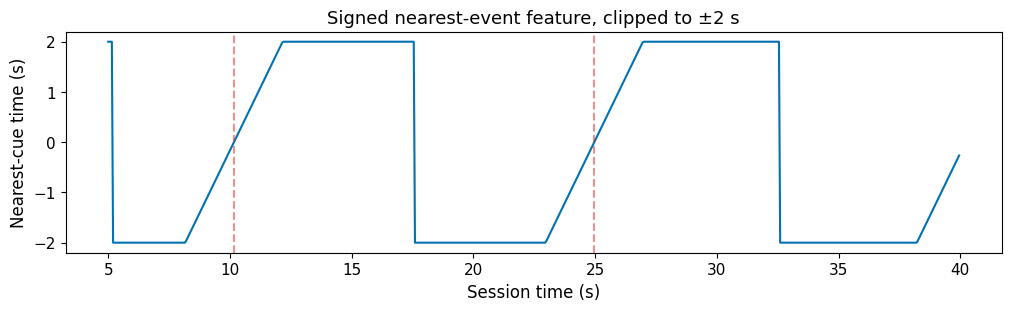

In [7]:
sample_times = np.arange(5.0, 40.0, 0.05)
nearest = time_to_nearest_event(sample_times, event_times, signed=True, max_time=2.0)
fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(sample_times, nearest)
for event in event_times[(event_times >= 5) & (event_times < 40)]:
    ax.axvline(event, color="tab:red", linestyle="--", alpha=0.5)
ax.set(xlabel="Session time (s)", ylabel="Nearest-cue time (s)", ylim=(-2.2, 2.2))
ax.set_title("Signed nearest-event feature, clipped to ±2 s")
plt.show()

For recorded inputs, [NWB I/O](09_nwb_io.ipynb) preserves spike identities and
acquisition windows. Use [Visualization](08_visualization.ipynb) to inspect
spatial fields and synchronized behavior on their original clock.